# 03 - Multimodal Visualization

## Objective

Compare the four MRI modalities of the same patient.

The notebook explores:
- Loading all four MRI modalities.
- Checking spatial alignment and consistency.
- Converting volumes to canonical RAS+ orientation.
- Comparing the same anatomical slices across modalities.
- Understanding the complementary information provided by each MRI sequence.
- Comparing intensity distributions across modalities.

Dataset: BraTS 2024 Adult Glioma
Patient: BraTS-GLI-02547-101

Modalities:
1. T1n
2. T1c
3. T2w
4. T2f (FLAIR)

In [3]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [5]:
# Define the dataset location
DATASET_ROOT = Path(
    "/kaggle/input/datasets/i212385nomanarif/2024-brats-glioma"
)

# Use the same patient as our previous notebooks
PATIENT_ID = "BraTS-GLI-02547-101"

PATIENT_DIR = DATASET_ROOT / PATIENT_ID

# Define the four MRI modalities
MODALITIES = {
    "T1n": f"{PATIENT_ID}-t1n.nii",
    "T1c": f"{PATIENT_ID}-t1c.nii",
    "T2w": f"{PATIENT_ID}-t2w.nii",
    "T2f (FLAIR)": f"{PATIENT_ID}-t2f.nii"
}

# Check whether all modality files exist
for modality, filename in MODALITIES.items():
    path = PATIENT_DIR / filename
    print(f"{modality}: {path.exists()}")

T1n: True
T1c: True
T2w: True
T2f (FLAIR): True


In [6]:
# Store the loaded NIfTI objects and their corresponding NumPy arrays
nii_images = {}
volumes = {}

for modality, filename in MODALITIES.items():

    # Load the NIfTI image
    nii = nib.load(str(PATIENT_DIR / filename))

    # Extract voxel data as a NumPy array
    volume = nii.get_fdata(dtype=np.float32)

    # Store both the image object and the voxel array
    nii_images[modality] = nii
    volumes[modality] = volume

    print(f"\n{modality}")
    print("Shape:", volume.shape)
    print("Data type:", volume.dtype)
    print("Min intensity:", volume.min())
    print("Max intensity:", volume.max())


T1n
Shape: (182, 218, 182)
Data type: float32
Min intensity: 0.0
Max intensity: 505.92276

T1c
Shape: (182, 218, 182)
Data type: float32
Min intensity: 0.0
Max intensity: 1253.4319

T2w
Shape: (182, 218, 182)
Data type: float32
Min intensity: 0.0
Max intensity: 1731.0282

T2f (FLAIR)
Shape: (182, 218, 182)
Data type: float32
Min intensity: 0.0
Max intensity: 443.10007


In [7]:
# Use T1n as our reference modality
reference = nii_images["T1n"]

for modality, nii in nii_images.items():

    print(f"\nChecking {modality}")

    # Check whether the dimensions match T1n
    print("Shape matches:",
          nii.shape == reference.shape)

    # Check whether the affine matrices match T1n
    print("Affine matches:",
          np.allclose(nii.affine, reference.affine))


Checking T1n
Shape matches: True
Affine matches: True

Checking T1c
Shape matches: True
Affine matches: True

Checking T2w
Shape matches: True
Affine matches: True

Checking T2f (FLAIR)
Shape matches: True
Affine matches: True


In [8]:
# Store canonical NIfTI objects and their corresponding volumes
canonical_images = {}
canonical_volumes = {}

for modality, nii in nii_images.items():

    # Convert the image to canonical RAS+ orientation
    nii_ras = nib.as_closest_canonical(nii)

    # Extract the reoriented voxel array
    volume_ras = nii_ras.get_fdata(dtype=np.float32)

    canonical_images[modality] = nii_ras
    canonical_volumes[modality] = volume_ras

    print(
        modality,
        nib.aff2axcodes(nii_ras.affine),
        volume_ras.shape
    )

T1n ('R', 'A', 'S') (182, 218, 182)
T1c ('R', 'A', 'S') (182, 218, 182)
T2w ('R', 'A', 'S') (182, 218, 182)
T2f (FLAIR) ('R', 'A', 'S') (182, 218, 182)


In [9]:
# Use T1n dimensions to determine the middle slice indices
D, H, W = canonical_volumes["T1n"].shape

x = D // 2
y = H // 2
z = W // 2

print("Sagittal index:", x)
print("Coronal index:", y)
print("Axial index:", z)

Sagittal index: 91
Coronal index: 109
Axial index: 91


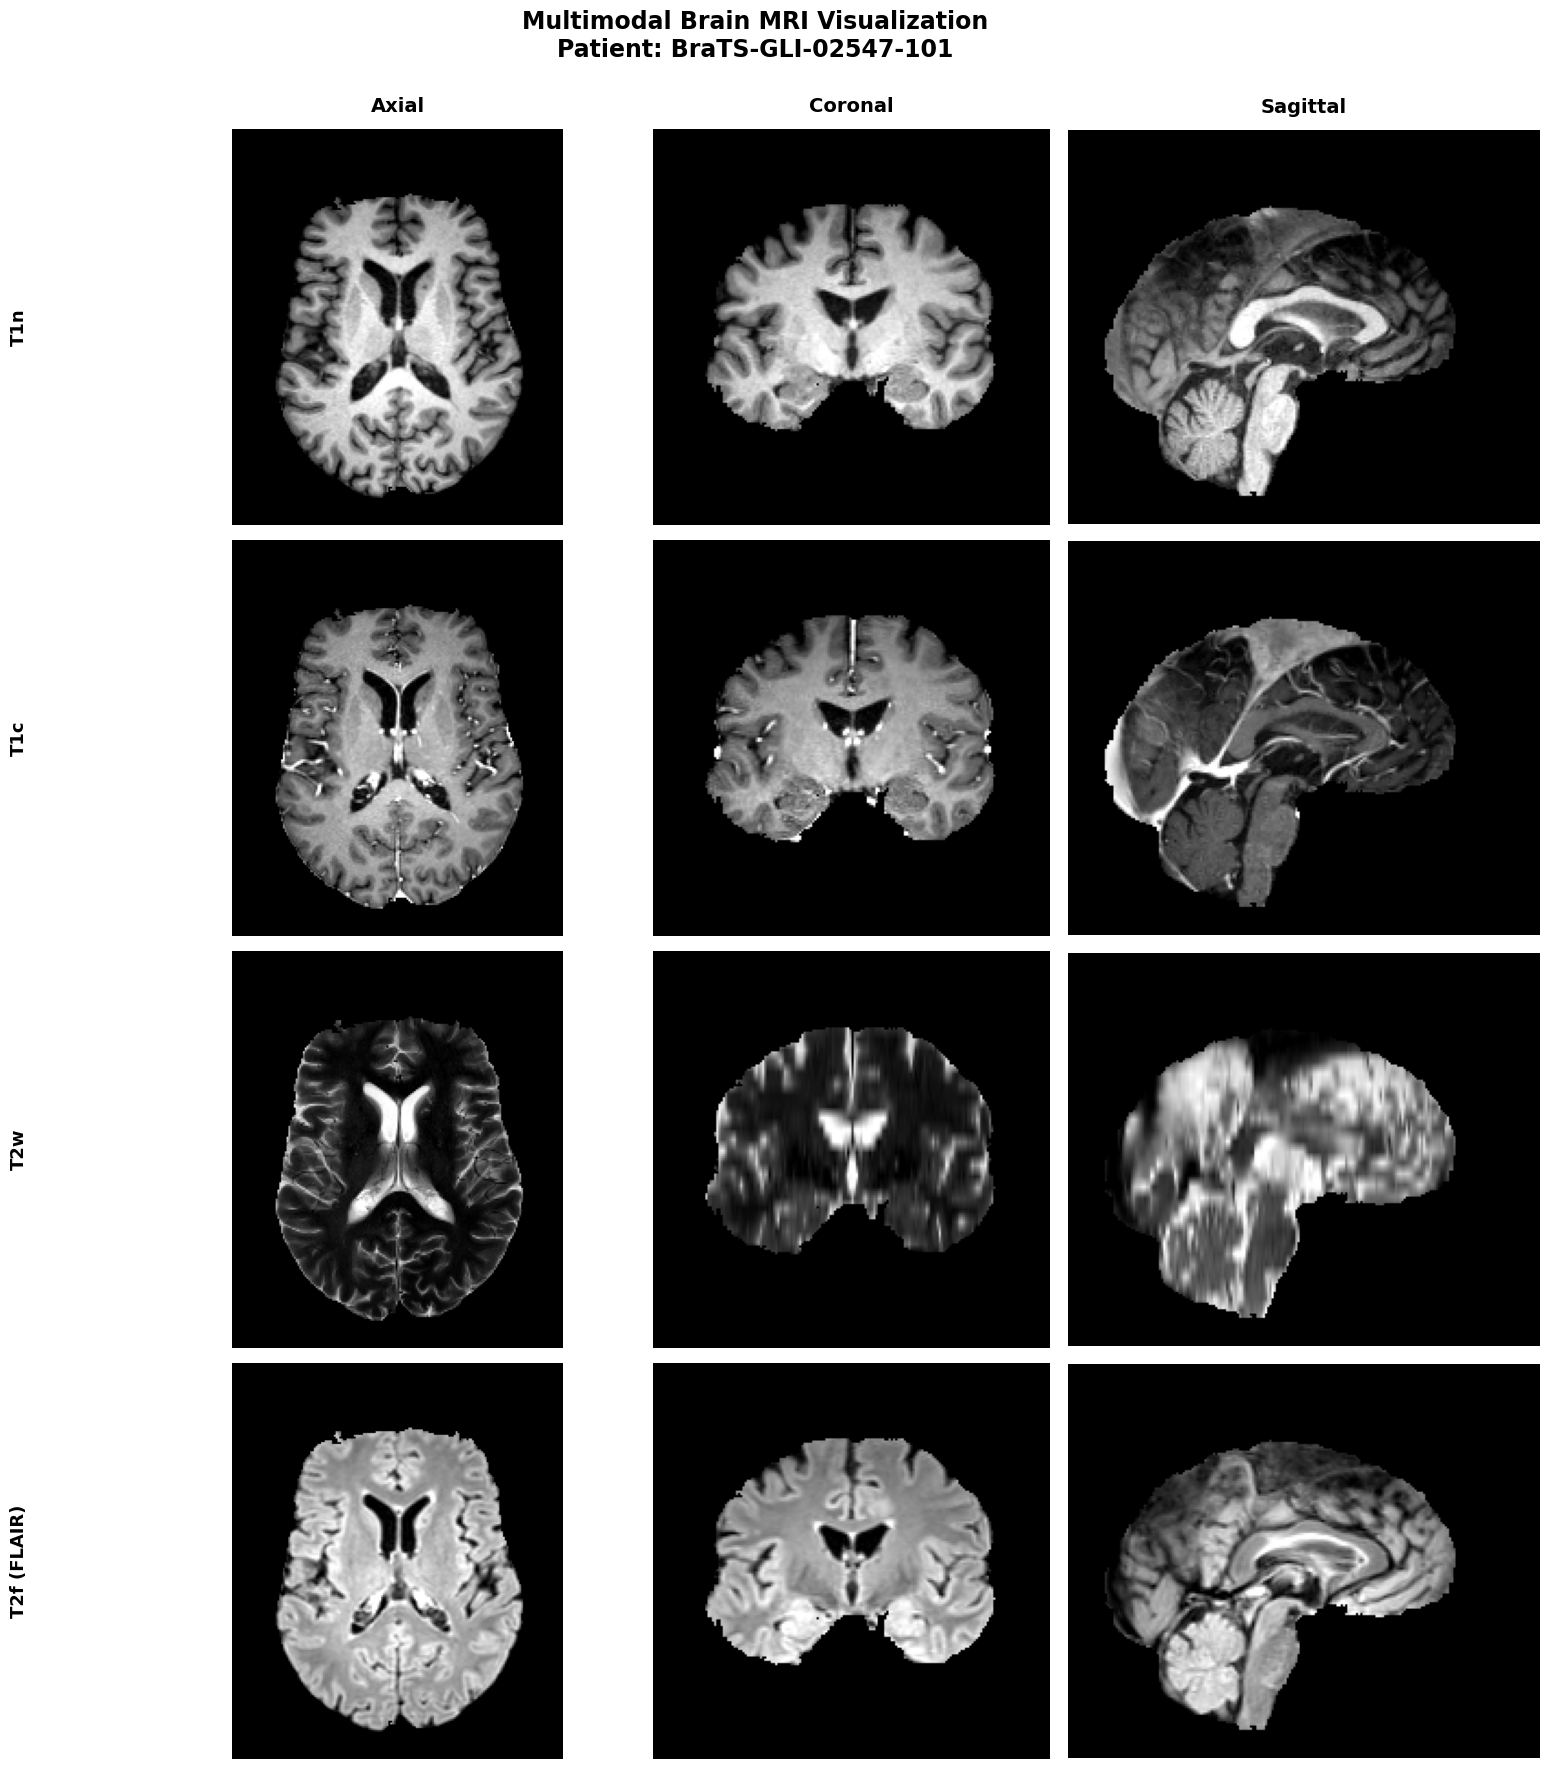

In [13]:
# Create a 4x3 grid:
# Rows represent MRI modalities.
# Columns represent anatomical planes.

fig, axes = plt.subplots(4, 3, figsize=(16, 18))

planes = ["Axial", "Coronal", "Sagittal"]

for row, (modality, volume) in enumerate(canonical_volumes.items()):

    # Extract the same anatomical locations from each modality
    axial = np.rot90(volume[:, :, z])
    coronal = np.rot90(volume[:, y, :])
    sagittal = np.rot90(volume[x, :, :])

    slices = [axial, coronal, sagittal]

    for col, slice_2d in enumerate(slices):

        # Calculate display limits using nonzero voxel intensities
        nonzero = slice_2d[slice_2d > 0]

        if nonzero.size > 0:
            vmin, vmax = np.percentile(nonzero, [1, 99])
        else:
            vmin, vmax = 0, 1

        # Display MRI slice
        axes[row, col].imshow(
            slice_2d,
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )

        # Add anatomical plane labels to the first row
        if row == 0:
            axes[row, col].set_title(
                planes[col],
                fontsize=14,
                fontweight="bold",
                pad=12
            )

        # Hide individual axes and ticks
        axes[row, col].axis("off")


# Adjust spacing to create room for modality labels
plt.tight_layout(rect=[0.12, 0, 1, 0.94])

# Draw the figure so that subplot positions are calculated
fig.canvas.draw()

# Add modality labels independently of individual axes
for row, modality in enumerate(canonical_volumes.keys()):

    # Get the vertical centre of the current row
    position = axes[row, 0].get_position()
    y_center = position.y0 + position.height / 2

    # Place modality label on the left side
    fig.text(
        0.04,
        y_center,
        modality,
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
        rotation=90
    )


# Overall figure title
fig.suptitle(
    f"Multimodal Brain MRI Visualization\nPatient: {PATIENT_ID}",
    fontsize=17,
    fontweight="bold"
)

plt.show()

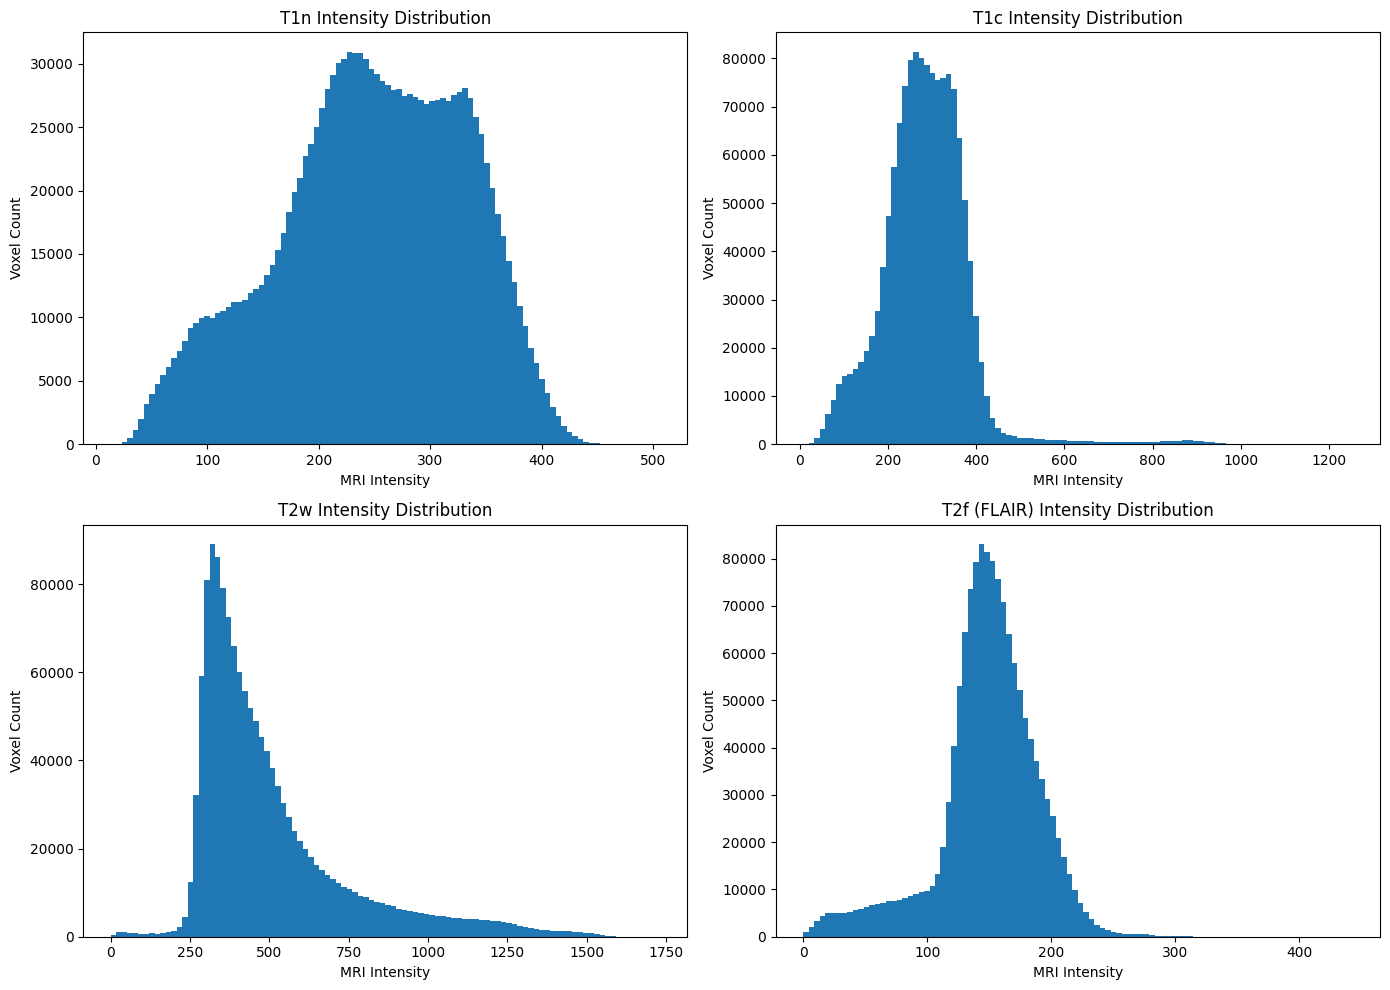

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Flatten the 2x2 axes array for easier iteration
axes = axes.flatten()

for ax, (modality, volume) in zip(
    axes, canonical_volumes.items()
):

    # Ignore zero-intensity background voxels
    nonzero = volume[volume > 0]

    # Plot the intensity distribution
    ax.hist(nonzero, bins=100)

    ax.set_title(f"{modality} Intensity Distribution")
    ax.set_xlabel("MRI Intensity")
    ax.set_ylabel("Voxel Count")

plt.tight_layout()
plt.show()

In [14]:
# Compare intensity statistics across all four MRI modalities

for modality, volume in canonical_volumes.items():

    # Consider only nonzero voxels
    nonzero = volume[volume > 0]

    print(f"\n{modality}")

    print("Mean:", np.mean(nonzero))
    print("Standard deviation:", np.std(nonzero))
    print("Median:", np.median(nonzero))
    print("1st percentile:", np.percentile(nonzero, 1))
    print("99th percentile:", np.percentile(nonzero, 99))


T1n
Mean: 246.97437
Standard deviation: 83.73867
Median: 251.20512
1st percentile: 55.669838
99th percentile: 401.5567

T1c
Mean: 284.9389
Standard deviation: 101.013916
Median: 283.37213
1st percentile: 74.716095
99th percentile: 672.0205

T2w
Mean: 506.16083
Standard deviation: 243.04968
Median: 428.13852
1st percentile: 233.08797
99th percentile: 1344.6565

T2f (FLAIR)
Mean: 148.68407
Standard deviation: 40.974316
Median: 151.01562
1st percentile: 20.46959
99th percentile: 232.09586
